# TSO-DTF - Final results and graphs (Google Colab)

Re-computes every final result **from the saved forecasts** and draws all result graphs:
base paper DTF (replicated) vs the proposed TSO-DTF (equal-weight ensemble of Opt 4, 5, 6, 7 and 10).

**Needs (already in your Drive):** `m5_data` (calendar, sell_prices, sales_train_evaluation) and in `m5_results`:
`baseline_predictions.csv.gz`, `optimization4_predictions.csv.gz`, `optimization5_predictions.csv.gz`,
`optimization6_predictions.csv.gz`, `optimization7_predictions.csv.gz`, `optimization10_predictions.csv.gz`, `eval_products.csv`.

**Run:** Runtime -> Run all (about 5-10 minutes, no model training).

In [1]:
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/m5_data"
RES_DIR = "/content/drive/MyDrive/m5_results"


Mounted at /content/drive


## Step 1 - Load data and forecasts

In [2]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon
plt.rcParams.update({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e8e8e8", "axes.axisbelow": True, "figure.dpi": 110})
BASE, OURS, NEG = "#9a9a95", "#2a78d6", "#d03b3b"
FIG_DIR = f"{RES_DIR}/final_figures"; os.makedirs(FIG_DIR, exist_ok=True)
def find(name):
    hits = glob.glob(f"{RES_DIR}/**/{name}", recursive=True)
    if not hits: raise FileNotFoundError(f"{name} not found in {RES_DIR}")
    return hits[0]

pp = pd.read_csv(find("eval_products.csv"))                     # the 9,119 scored series (same for every method)
cal = pd.read_csv(f"{DATA_DIR}/calendar.csv", parse_dates=["date"])
sales = pd.concat([ch[ch["store_id"].isin(["CA_1", "TX_1", "WI_1"])] for ch in pd.read_csv(f"{DATA_DIR}/sales_train_evaluation.csv", chunksize=3000)])
sales = pp[["store_id", "item_id"]].merge(sales, on=["store_id", "item_id"], how="left")
dcols = [c for c in sales.columns if c.startswith("d_")]
Y = sales[dcols].values.astype(float); N = len(pp)
T0 = int(np.where(cal["date"].values[:len(dcols)] == np.datetime64("2016-03-22"))[0][0]); T = 62
A = Y[:, T0:T0 + T]                                             # actual sales in the test period
print(f"{N:,} series | test {cal.date.iloc[T0].date()} to {cal.date.iloc[T0 + T - 1].date()} ({T} days)")

def load_pred(fname):
    p = pd.read_csv(find(fname), parse_dates=["date"])
    p = pp[["store_id", "item_id"]].reset_index().merge(p, on=["store_id", "item_id"]).sort_values(["index", "date"])
    assert len(p) == N * T, f"{fname}: {len(p)} rows, expected {N * T}"
    assert np.allclose(p["sales"].values.reshape(N, T), A), f"{fname}: actuals do not match"
    return np.maximum(p["pred"].values.reshape(N, T), 0)
F = {"Baseline DTF": load_pred("baseline_predictions.csv.gz"),
     "Opt 4": load_pred("optimization4_predictions.csv.gz"), "Opt 5": load_pred("optimization5_predictions.csv.gz"),
     "Opt 6": load_pred("optimization6_predictions.csv.gz"), "Opt 7": load_pred("optimization7_predictions.csv.gz"),
     "Opt 10": load_pred("optimization10_predictions.csv.gz")}
F["Ensemble 4+5"] = (F["Opt 4"] + F["Opt 5"]) / 2
F["TSO-DTF (final)"] = (F["Opt 4"] + F["Opt 5"] + F["Opt 6"] + F["Opt 7"] + F["Opt 10"]) / 5   # equal-weight ensemble
print("Loaded:", list(F))


9,119 series | test 2016-03-22 to 2016-05-22 (62 days)
Loaded: ['Baseline DTF', 'Opt 4', 'Opt 5', 'Opt 6', 'Opt 7', 'Opt 10', 'Ensemble 4+5', 'TSO-DTF (final)']


## Step 2 - Evaluation metrics (base paper Eq. 1-2, M5 WRMSSE, MAE, RMSE, WAPE)

In [3]:
first = np.argmax(Y[:, :T0] > 0, axis=1)
scale = np.array([np.mean(np.diff(Y[i, first[i]:T0]) ** 2) for i in range(N)])          # RMSSE scale (from first sale)
mad = np.mean(np.abs(np.diff(Y[:, T0 - 365:T0], axis=1)), axis=1)                         # SME scale (365-day history)
w = pp["weight"].values
def product_metrics(P):
    e = A - P; r = np.sqrt(np.mean(e ** 2, axis=1) / scale)
    return {"WRMSSE (product level)": (w * r).sum() / w.sum(), "RMSSE mean (Eq. 1)": r.mean(), "RMSSE median": np.median(r),
            "RMSE": np.sqrt((e ** 2).mean()), "MAE": np.abs(e).mean(), "WAPE": np.abs(e).sum() / A.sum(),
            "SME bias (Eq. 2)": np.nanmean(np.mean(e, axis=1) / mad)}, r

# ---- official M5 multi-level WRMSSE ----
prices = pd.concat([ch[ch["store_id"].isin(["CA_1", "TX_1", "WI_1"])] for ch in pd.read_csv(f"{DATA_DIR}/sell_prices.csv", chunksize=500000)])
pm = prices.pivot_table(index=["store_id", "item_id"], columns="wm_yr_wk", values="sell_price").reindex(pd.MultiIndex.from_frame(pp[["store_id", "item_id"]]))
wk = cal["wm_yr_wk"].values[:len(dcols)]
P28 = pm.reindex(columns=wk[T0 - 28:T0]).values
rev28 = np.nansum(Y[:, T0 - 28:T0] * np.nan_to_num(P28), axis=1)                           # weights: revenue 28 days before test
dept = np.array([i.rsplit("_", 1)[0] for i in pp.item_id]); catg = np.array([i.split("_")[0] for i in pp.item_id]); st = pp.store_id.values
LEVELS = {"Total": np.zeros(N, int), "Store": st, "Category": catg, "Department": dept, "Store-category": np.char.add(st, catg),
          "Store-department": np.char.add(st, dept), "Product (all stores)": pp.item_id.values, "Product-store": np.arange(N)}
OFFICIAL_12 = ["Total", "Store", "Store", "Category", "Department", "Store-category", "Store-category",
               "Store-department", "Store-department", "Product (all stores)", "Product-store", "Product-store"]  # 1 store per state
PRE = {}
for lv, g in LEVELS.items():
    codes = pd.Series(g).astype("category").cat.codes.values; K = codes.max() + 1
    agg = lambda M, codes=codes, K=K: np.vstack([np.bincount(codes, weights=M[:, t], minlength=K) for t in range(M.shape[1])]).T
    Yh = agg(Y[:, :T0]); sc = np.array([np.mean(np.diff(y[np.argmax(y > 0):]) ** 2) for y in Yh])
    wl = np.bincount(codes, weights=rev28, minlength=K); ok = sc > 0
    PRE[lv] = (codes, K, agg, agg(A)[ok], sc[ok], wl[ok] / wl[ok].sum(), ok)
def level_wrmsse(P, lv, days=slice(None)):
    codes, K, agg, Aa, sc, wl, ok = PRE[lv]; Pa = agg(P)[ok]
    return (wl * np.sqrt(np.mean((Aa[:, days] - Pa[:, days]) ** 2, axis=1) / sc)).sum()
def official(P, days=slice(None)):
    return np.mean([level_wrmsse(P, lv, days) for lv in OFFICIAL_12])

B, E = F["Baseline DTF"], F["TSO-DTF (final)"]
mb, rb = product_metrics(B); me, re_ = product_metrics(E)
rows = [["Official M5 WRMSSE (12 levels)", official(B), official(E)]] + [[k, mb[k], me[k]] for k in mb]
tab = pd.DataFrame(rows, columns=["Metric", "Base paper DTF", "TSO-DTF"])
tab["Improvement %"] = np.where(tab.Metric.str.startswith("SME"), 100 * (tab["Base paper DTF"].abs() - tab["TSO-DTF"].abs()) / tab["Base paper DTF"].abs(),
                                100 * (tab["Base paper DTF"] - tab["TSO-DTF"]) / tab["Base paper DTF"])
print(tab.round(4).to_string(index=False))
print(f"\nProducts improved: {100 * np.mean(re_ < rb):.1f}%   Wilcoxon p = {wilcoxon(re_, rb).pvalue:.1e}")


                        Metric  Base paper DTF  TSO-DTF  Improvement %
Official M5 WRMSSE (12 levels)          0.5563   0.5392         3.0773
        WRMSSE (product level)          0.8069   0.7998         0.8847
            RMSSE mean (Eq. 1)          0.7302   0.7260         0.5704
                  RMSSE median          0.7000   0.6957         0.6100
                          RMSE          1.7588   1.7372         1.2268
                           MAE          0.9307   0.9234         0.7867
                          WAPE          0.7093   0.7037         0.7867
              SME bias (Eq. 2)          0.0067  -0.0013        80.6773

Products improved: 64.2%   Wilcoxon p = 8.7e-223


## Step 3 - Multi-level table and bootstrap confidence interval

In [4]:
lvl = pd.DataFrame([[lv, level_wrmsse(B, lv), level_wrmsse(E, lv)] for lv in LEVELS], columns=["Level", "Base paper DTF", "TSO-DTF"])
lvl["Improvement %"] = 100 * (lvl["Base paper DTF"] - lvl["TSO-DTF"]) / lvl["Base paper DTF"]
ob, oe = official(B), official(E)
lvl.loc[len(lvl)] = ["Official M5 score (12 levels)", ob, oe, 100 * (ob - oe) / ob]
print(lvl.round(4).to_string(index=False))
rng = np.random.default_rng(0); blocks = [np.arange(i, min(i + 7, T)) for i in range(0, T, 7)]
boot = []
for _ in range(1000):
    d = np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))])
    boot.append(100 * (official(B, d) - official(E, d)) / official(B, d))
print(f"\nBlock-bootstrap 95% CI of the improvement: [{np.percentile(boot, 2.5):.2f}%, {np.percentile(boot, 97.5):.2f}%]")


                        Level  Base paper DTF  TSO-DTF  Improvement %
                        Total          0.3847   0.3602         6.3769
                        Store          0.4407   0.4273         3.0368
                     Category          0.4314   0.4048         6.1669
                   Department          0.5002   0.4625         7.5384
               Store-category          0.5069   0.4920         2.9502
             Store-department          0.5720   0.5511         3.6680
         Product (all stores)          0.7653   0.7579         0.9671
                Product-store          0.7775   0.7722         0.6786
Official M5 score (12 levels)          0.5563   0.5392         3.0773

Block-bootstrap 95% CI of the improvement: [0.67%, 4.92%]


## Step 4 - Ablation (each optimization step vs the base paper)

In [5]:
abl = []
for k in ["Opt 4", "Opt 5", "Opt 6", "Opt 7", "Opt 10", "Ensemble 4+5", "TSO-DTF (final)"]:
    m, _ = product_metrics(F[k])
    abl.append([k, 100 * (mb["WRMSSE (product level)"] - m["WRMSSE (product level)"]) / mb["WRMSSE (product level)"], 100 * (ob - official(F[k])) / ob])
abl = pd.DataFrame(abl, columns=["Method", "WRMSSE product level %", "Official M5 score %"])
print(abl.round(2).to_string(index=False))


         Method  WRMSSE product level %  Official M5 score %
          Opt 4                    0.48                 1.29
          Opt 5                    0.60                 1.51
          Opt 6                    0.71                 1.79
          Opt 7                    0.72                 1.36
         Opt 10                    0.67                 2.15
   Ensemble 4+5                    0.73                 2.40
TSO-DTF (final)                    0.88                 3.08


## Step 5 - Result graphs

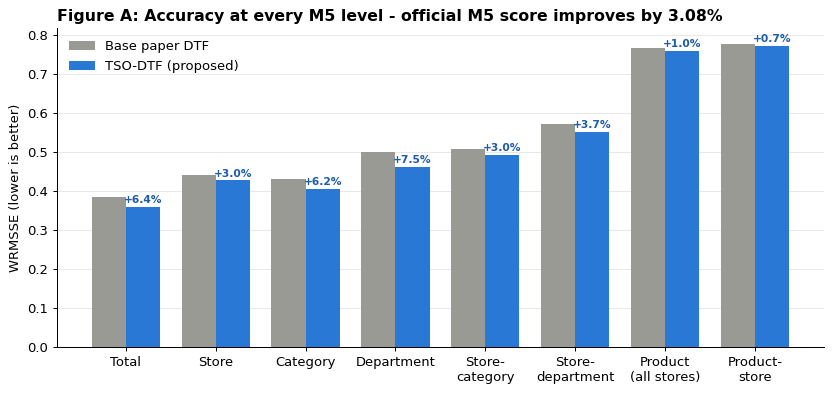

In [6]:
# Figure A - every M5 level
lv = list(LEVELS); x = np.arange(len(lv)); vb = lvl["Base paper DTF"][:len(lv)].values; ve = lvl["TSO-DTF"][:len(lv)].values
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(x - .19, vb, .38, color=BASE, label="Base paper DTF"); ax.bar(x + .19, ve, .38, color=OURS, label="TSO-DTF (proposed)")
for i in range(len(lv)): ax.text(x[i] + .19, ve[i] + .01, f"+{100 * (vb[i] - ve[i]) / vb[i]:.1f}%", ha="center", fontsize=8.5, color="#1c5cab", fontweight="bold")
ax.set_xticks(x, [l.replace(" (", "\n(").replace("-", "-\n") for l in lv]); ax.set_ylabel("WRMSSE (lower is better)"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_title(f"Figure A: Accuracy at every M5 level - official M5 score improves by {100 * (ob - oe) / ob:.2f}%", loc="left", fontweight="bold")
fig.savefig(f"{FIG_DIR}/figA_multilevel.png", dpi=250, bbox_inches="tight"); plt.show()


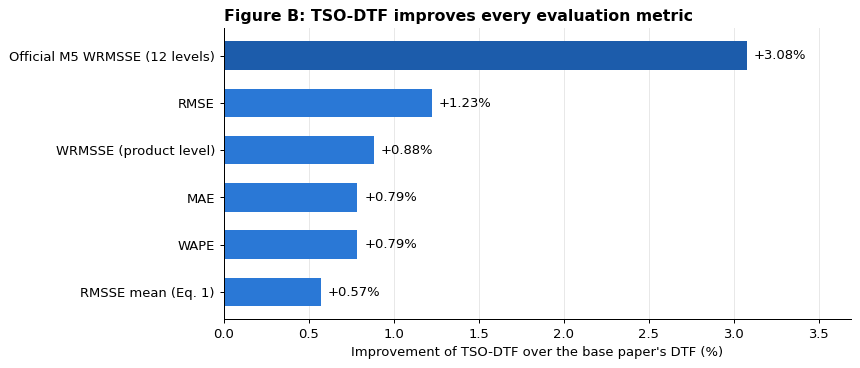

In [7]:
# Figure B - improvement on every metric
mm = tab[~tab.Metric.str.startswith(("SME", "RMSSE median"))].set_index("Metric")["Improvement %"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(mm.index, mm.values, color=["#1c5cab" if k.startswith("Official") else OURS for k in mm.index], height=.6)
for i, v in enumerate(mm.values): ax.text(v + .04, i, f"+{v:.2f}%", va="center")
ax.set_xlabel("Improvement of TSO-DTF over the base paper's DTF (%)"); ax.set_xlim(0, mm.max() * 1.2); ax.grid(axis="y", visible=False)
ax.set_title("Figure B: TSO-DTF improves every evaluation metric", loc="left", fontweight="bold")
fig.savefig(f"{FIG_DIR}/figB_metrics.png", dpi=250, bbox_inches="tight"); plt.show()


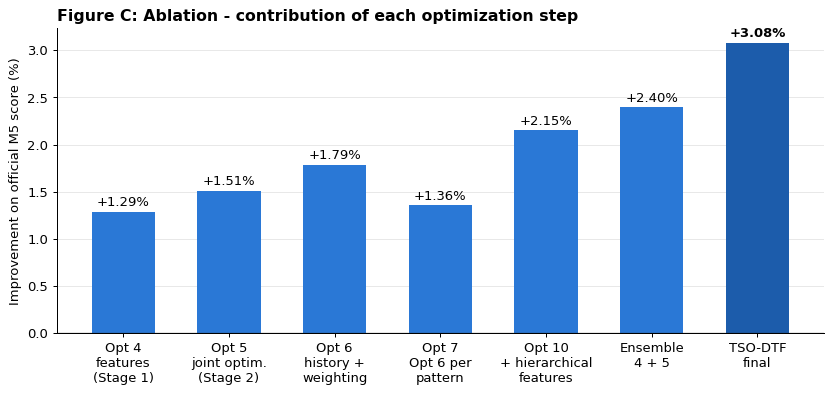

In [8]:
# Figure C - ablation
fig, ax = plt.subplots(figsize=(11, 4.4)); xa = np.arange(len(abl)); va = abl["Official M5 score %"].values
ax.bar(xa, va, color=[NEG if v < 0 else ("#1c5cab" if i == len(abl) - 1 else OURS) for i, v in enumerate(va)], width=.6)
for i, v in enumerate(va): ax.text(i, v + .06, f"{v:+.2f}%", ha="center", fontweight="bold" if i == len(abl) - 1 else "normal")
ax.set_xticks(xa, ["Opt 4\nfeatures\n(Stage 1)", "Opt 5\njoint optim.\n(Stage 2)", "Opt 6\nhistory +\nweighting", "Opt 7\nOpt 6 per\npattern",
                   "Opt 10\n+ hierarchical\nfeatures", "Ensemble\n4 + 5", "TSO-DTF\nfinal"])
ax.axhline(0, color="#333", lw=1); ax.grid(axis="x", visible=False); ax.set_ylabel("Improvement on official M5 score (%)")
ax.set_title("Figure C: Ablation - contribution of each optimization step", loc="left", fontweight="bold")
fig.savefig(f"{FIG_DIR}/figC_ablation.png", dpi=250, bbox_inches="tight"); plt.show()


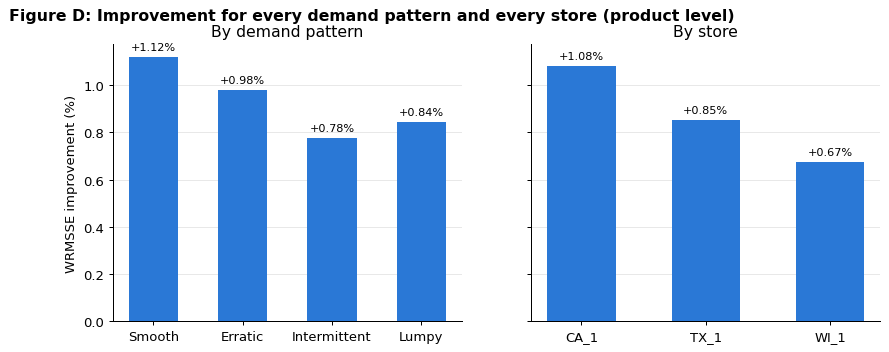

In [9]:
# Figure D - by demand pattern and store
def W(P, mask): _, r = product_metrics(P); return (w[mask] * r[mask]).sum() / w[mask].sum()
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, key, groups in [(axs[0], pp.category.values, ["smooth", "erratic", "intermittent", "lumpy"]), (axs[1], st, ["CA_1", "TX_1", "WI_1"])]:
    imp = [100 * (W(B, key == g) - W(E, key == g)) / W(B, key == g) for g in groups]
    ax.bar([g.capitalize() if g.islower() else g for g in groups], imp, color=OURS, width=.55)
    for i, v in enumerate(imp): ax.text(i, v + .03, f"{v:+.2f}%", ha="center", fontsize=9)
    ax.grid(axis="x", visible=False)
axs[0].set_title("By demand pattern"); axs[1].set_title("By store"); axs[0].set_ylabel("WRMSSE improvement (%)")
fig.suptitle("Figure D: Improvement for every demand pattern and every store (product level)", x=.02, ha="left", fontweight="bold")
fig.savefig(f"{FIG_DIR}/figD_pattern_store.png", dpi=250, bbox_inches="tight"); plt.show()


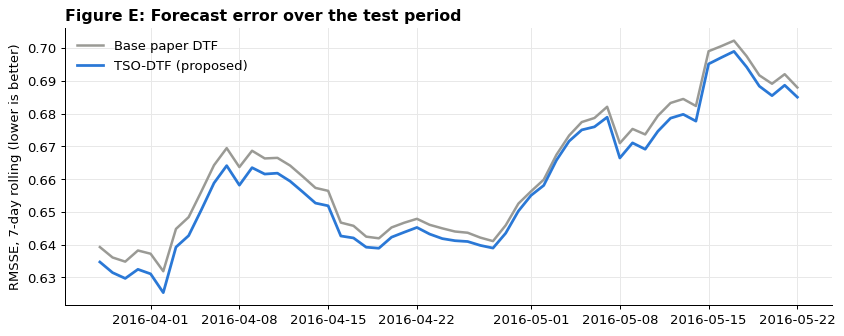

In [10]:
# Figure E - error over the test period
def roll(P):
    c = np.cumsum(np.pad((A - P) ** 2, ((0, 0), (1, 0))), axis=1); return np.sqrt(((c[:, 7:] - c[:, :-7]) / 7) / scale[:, None]).mean(0)
dts = pd.date_range("2016-03-28", periods=T - 6)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(dts, roll(B), color=BASE, lw=2, label="Base paper DTF"); ax.plot(dts, roll(E), color=OURS, lw=2.2, label="TSO-DTF (proposed)")
ax.set_ylabel("RMSSE, 7-day rolling (lower is better)"); ax.legend(frameon=False)
ax.set_title("Figure E: Forecast error over the test period", loc="left", fontweight="bold")
fig.savefig(f"{FIG_DIR}/figE_over_time.png", dpi=250, bbox_inches="tight"); plt.show()


All figures saved in /content/drive/MyDrive/m5_results/final_figures


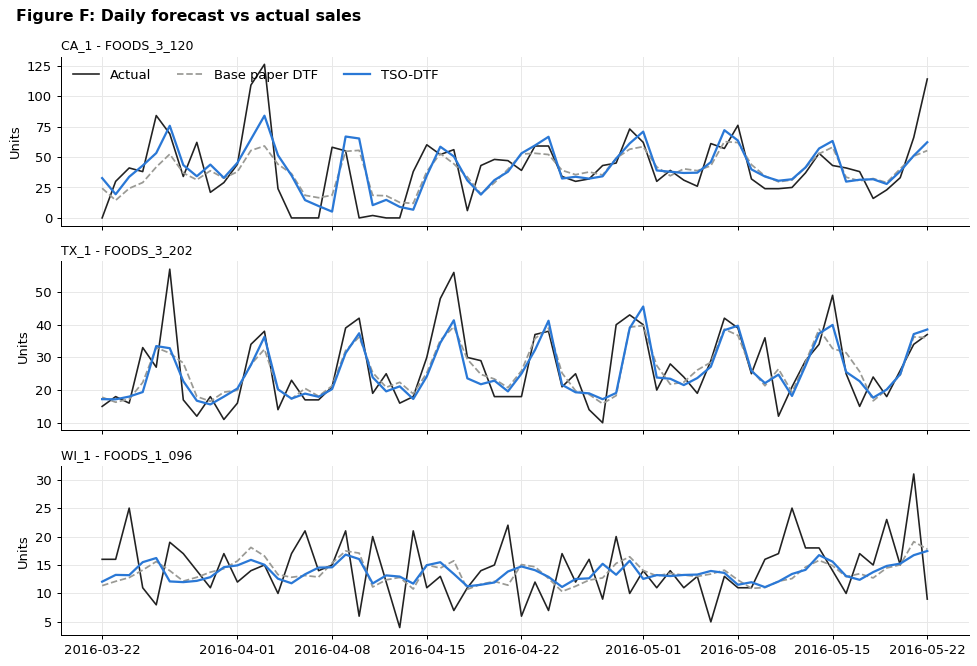

In [11]:
# Figure F - forecast vs actual for the best-selling product of each store
order = np.argsort(-w); picks = [next(i for i in order if st[i] == s) for s in ["CA_1", "TX_1", "WI_1"]]
fig, axs = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True); dd = pd.date_range("2016-03-22", periods=T)
for ax, i in zip(axs, picks):
    ax.plot(dd, A[i], color="#222", lw=1.3, label="Actual"); ax.plot(dd, B[i], color=BASE, lw=1.4, ls="--", label="Base paper DTF")
    ax.plot(dd, E[i], color=OURS, lw=1.8, label="TSO-DTF"); ax.set_title(f"{st[i]} - {pp.item_id[i]}", loc="left", fontsize=10); ax.set_ylabel("Units")
axs[0].legend(frameon=False, ncol=3, loc="upper left")
fig.suptitle("Figure F: Daily forecast vs actual sales", x=.02, ha="left", fontweight="bold"); fig.tight_layout()
fig.savefig(f"{FIG_DIR}/figF_forecast_vs_actual.png", dpi=250, bbox_inches="tight"); plt.show()
print("All figures saved in", FIG_DIR)
